In [203]:
import pandas as pd
import os
import random
import time
from sklearn.model_selection import train_test_split
import torch
import torchvision
from torch.utils.data import DataLoader, TensorDataset, Dataset,  WeightedRandomSampler
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torchvision.transforms as transforms
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold
from tqdm import tqdm
from torchvision import models
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [204]:
!nvidia-smi

Tue Dec 16 16:24:17 2025       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.183.01             Driver Version: 535.183.01   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA RTX A6000               Off | 00000000:01:00.0 Off |                  Off |
| 30%   49C    P2              84W / 300W |   5986MiB / 49140MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [205]:
torch.manual_seed(42)

In [206]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [207]:
train_path = '/home/dbtproject/barsha/Image/training_set' 
test_path = '/home/dbtproject/barsha/Image/test_set'

In [208]:
# Show the paths and their types (use type() on a Python object)
print('type(train_path):', type(train_path))

type(train_path): <class 'str'>


In [209]:
print('The training set consists of ', len(os.listdir(train_path +'/Class0_Graminicola')),
 ' Class0_Graminicola images,', len(os.listdir(train_path + '/Class1_Incognita')), 
 'Class1_Incognita images and ', len(os.listdir(train_path + '/Class2_Javanica')), ' Class2_Javanica images.' )

The training set consists of  139  Class0_Graminicola images, 55 Class1_Incognita images and  83  Class2_Javanica images.


In [210]:
print('The test set consists of ', len(os.listdir(test_path +'/Class0_Graminicola')), 
 ' Class0_Graminicola images,', len(os.listdir(test_path +'/Class1_Incognita')), 
 'Class1_Incognita images and ', len(os.listdir(test_path +'/Class2_Javanica')), ' Class2_Javanica images.' )

The test set consists of  35  Class0_Graminicola images, 14 Class1_Incognita images and  21  Class2_Javanica images.


In [211]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


In [212]:
import os
import pandas as pd
from PIL import Image

def images_to_dataframe(root_dir):
    rows = []

    # root_dir should contain subfolders (classes)
    for label in os.listdir(root_dir):
        class_path = os.path.join(root_dir, label)
        if not os.path.isdir(class_path):
            continue

        for filename in os.listdir(class_path):
            file_path = os.path.join(class_path, filename)

            # Open the image to get size
            try:
                with Image.open(file_path) as img:
                    width, height = img.size
            except:
                continue
            
            rows.append({
                "filename": filename,
                "path": file_path,
                "label": label,
            
            })

    return pd.DataFrame(rows)


# Example: train and test DataFrames
train_df = images_to_dataframe("/home/dbtproject/barsha/Image/training_set")
test_df = images_to_dataframe("/home/dbtproject/barsha/Image/test_set")

print(train_df.head())
print(train_df.shape)
print(test_df.shape)


              filename                                               path  \
0       S-57_PP_4.tiff  /home/dbtproject/barsha/Image/training_set/Cla...   
1       D-30_PP_5.tiff  /home/dbtproject/barsha/Image/training_set/Cla...   
2  D-38_PP_Good_4.tiff  /home/dbtproject/barsha/Image/training_set/Cla...   
3       ES-3_PP_4.tiff  /home/dbtproject/barsha/Image/training_set/Cla...   
4       G-60_PP_4.tiff  /home/dbtproject/barsha/Image/training_set/Cla...   

                label  
0  Class0_Graminicola  
1  Class0_Graminicola  
2  Class0_Graminicola  
3  Class0_Graminicola  
4  Class0_Graminicola  
(277, 3)
(70, 3)


In [213]:
train_df.head()

,filename,path,label
0,S-57_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
1,D-30_PP_5.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
2,D-38_PP_Good_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
3,ES-3_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
4,G-60_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola


In [214]:
train_df['label'].value_counts()


label
Class0_Graminicola    139
Class2_Javanica        83
Class1_Incognita       55
Name: count, dtype: int64

In [215]:
train_df.sample(5)


,filename,path,label
30,J-45_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
126,G-13_PP_1.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
220,Meloidogyne javanica_58.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class2_Javanica
142,Meloidogyne javanica_69.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class2_Javanica
255,Meloidogyne incognita_45.jpeg,/home/dbtproject/barsha/Image/training_set/Cla...,Class1_Incognita


In [216]:
le = LabelEncoder()
train_df['label'] = le.fit_transform(train_df['label'])
test_df['label'] = le.transform(test_df['label'])
train_df.head(150)

 

,filename,path,label
0,S-57_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
1,D-30_PP_5.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
2,D-38_PP_Good_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
3,ES-3_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
4,G-60_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
...,...,...,...
145,Meloidogyne javanica_6.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,2
146,Meloidogyne javanica_73.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,2
147,Meloidogyne javanica_40.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,2
148,Meloidogyne javanica_76.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,2


In [217]:
test_df.head()

,filename,path,label
0,Chaibasa_12_PP_2.tiff,/home/dbtproject/barsha/Image/test_set/Class0_...,0
1,Chaibasa_71_PP_3.tiff,/home/dbtproject/barsha/Image/test_set/Class0_...,0
2,Chaibasa_1.tiff,/home/dbtproject/barsha/Image/test_set/Class0_...,0
3,Chaibasa_12_PP_1.tiff,/home/dbtproject/barsha/Image/test_set/Class0_...,0
4,Chaibasa_2_PP_2.tiff,/home/dbtproject/barsha/Image/test_set/Class0_...,0


In [218]:
# train_df = train_df.drop(columns=['label'])
# test_df = test_df.drop(columns=['label'])

In [219]:
RANDOM_STATE = 42
VAL_SIZE = 0.20   # 10% validation

train_df, val_df = train_test_split(
    train_df,
    test_size=VAL_SIZE,
    stratify=train_df['label'],
    random_state=RANDOM_STATE
)

print("After split:")
print("Train split counts:\n", train_df['label'].value_counts().sort_index())
print("Val split counts:\n", val_df['label'].value_counts().sort_index())


After split:
Train split counts:
 label
0    111
1     44
2     66
Name: count, dtype: int64
Val split counts:
 label
0    28
1    11
2    17
Name: count, dtype: int64


In [220]:
(train_df.shape,
val_df.shape
)

((221, 3), (56, 3))

In [221]:
class DFImageDataset(Dataset):
    def __init__(self, df, img_col='path', label_col='label', transform=None):
        
        self.df = df.reset_index(drop=True)
        self.img_col = img_col
        self.label_col = label_col
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = row[self.img_col]
        # load image (PIL)
        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        else:
            # default
            img = transforms.ToTensor()(img)
        label = int(row[self.label_col])
        return img, label


In [222]:
train_df['label'].unique()


array([0, 2, 1])

In [223]:
val_df['label'].unique()

array([0, 2, 1])

In [224]:
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),  # Resize images to a common size
    transforms.CenterCrop((224,224)),
    transforms.RandomHorizontalFlip(),  # Data augmentation
    transforms.RandomVerticalFlip(),  # Data augmentation
    transforms.RandomRotation(degrees=(-10,10)), # Randomly rotate images
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normalize with ImageNet stats
])

val_test_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [225]:

train_data = DFImageDataset(train_df, img_col='path', label_col='label', transform=train_transform)
val_data   = DFImageDataset(val_df,   img_col='path', label_col='label', transform=val_test_transform)
test_data  = DFImageDataset(test_df,  img_col='path', label_col='label', transform=val_test_transform)


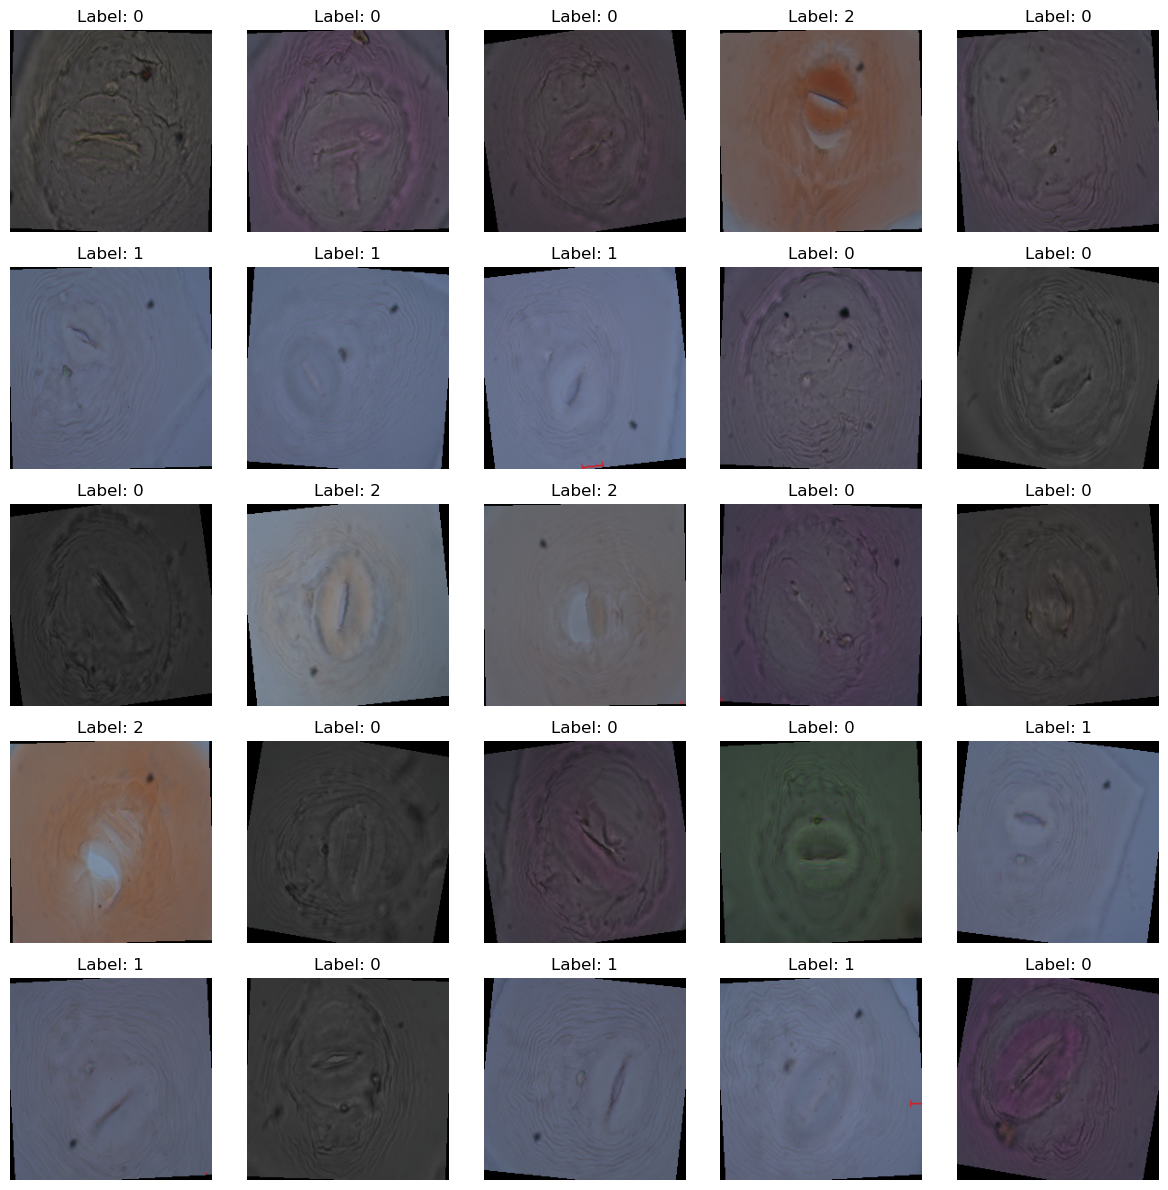

In [226]:
n_rows =5
n_cols =5
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 12))
axes = axes.flatten()
for row in range(n_rows):
    for col in range(n_cols):
        idx = row * n_cols + col
        img, label = train_data[idx]
        img = img.permute(1, 2, 0).numpy()  # Convert from (C, H, W) to (H, W, C)
        img = np.clip(img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]), 0, 1)  # Unnormalize
        axes[idx].imshow(img)
        axes[idx].set_title(f'Label: {label}')
        axes[idx].axis('off')
plt.tight_layout()
plt.show()

In [227]:
# get labels as numpy array from train_df (the split)
train_labels = train_df['label'].values
classes, class_counts = np.unique(train_labels, return_counts=True)
print("Classes:", classes)
print("Class counts:", class_counts)

# weight per class: inverse of count
class_weights = {cls: 1.0 / count for cls, count in zip(classes, class_counts)}
print("Class weights:", class_weights)

# sample weight for each sample in the training split
sample_weights = train_df['label'].map(class_weights).values  # pandas Series -> numpy

# convert to torch tensor
sample_weights_tensor = torch.from_numpy(sample_weights.astype(np.float32))

# create WeightedRandomSampler
num_samples = len(sample_weights_tensor)   # usually equals len(train_dataset)
sampler = WeightedRandomSampler(weights=sample_weights_tensor, num_samples=num_samples, replacement=True)


Classes: [0 1 2]
Class counts: [111  44  66]
Class weights: {np.int64(0): np.float64(0.009009009009009009), np.int64(1): np.float64(0.022727272727272728), np.int64(2): np.float64(0.015151515151515152)}


In [228]:
len(train_df)

221

In [251]:
#configuration
NUM_EPOCHS = 20
LR = 0.001
BATCH_SIZE = 32
weight_decay = 0.01
NUM_WORKERS = 4
PIN_MEMORY = True
# Path to checkpoint file (use a project-local checkpoints directory)
import os
CHECKPOINT_DIR = os.path.join('/home/dbtproject/barsha/np_code_new', 'checkpoints')
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, 'resnet50_best_model.pth')
# os.makedirs(os.path.dirname(CHECKPOINT_PATH) or '.', exist_ok=True)


In [252]:

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    sampler=sampler,  # use the weighted sampler
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

In [253]:
# skf = StratifiedKFold(n_splits=NUM_FOLDS, shuffle=True, random_state=SEED)

In [254]:
num_classes =len(train_data.df['label'].unique())
num_classes

3

In [255]:
model = torchvision.models.vgg16(pretrained=True)
# Replace the final fully connected layer:
# ResNet50's fc input features:
# in_features = model.fc.in_features
# model.fc = nn.Linear(in_features, num_classes)

/home/anaconda3/envs/new_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/anaconda3/envs/new_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [256]:
model

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [257]:
model.classifier

Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=4096, out_features=1000, bias=True)
)

In [258]:
# model.to(device)

In [259]:
for param in model.features.parameters():
    param.requires_grad = False

In [260]:
model.classifier=nn.Sequential(
    nn.Linear(25088, 1024),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(1024, 512),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(512, num_classes)
)
model.to(device)


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [261]:
model.classifier

Sequential(
  (0): Linear(in_features=25088, out_features=1024, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=1024, out_features=512, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=512, out_features=3, bias=True)
)

In [262]:
optimizer = optim.Adam(model.classifier.parameters(), lr=LR) 
# weight_decay=weight_decay
criterion = nn.CrossEntropyLoss()
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)
best_val_accuracy = 0.0


In [263]:
history = {'train_loss': [],
           'val_loss': [],
           'train_accuracy': [],
           'val_accuracy': [],
           'epoch': []}

In [264]:
import copy
import os
for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()
    print(f'Epoch {epoch}/{NUM_EPOCHS}')
    
    # Training phase
    model.train()
    running_loss = 0.0
    running_correct = 0
    running_total = 0

    train_bar = tqdm(train_loader, desc=f'Epoch {epoch}/{NUM_EPOCHS} - Training', leave=False)
    for inputs, labels in train_bar:
        inputs, labels = inputs.to(device), labels.to(device)
        batch_size = inputs.size(0)

        optimizer.zero_grad()

        outputs = model(inputs.float())
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_size #(0) #accumulate total loss
        _, predicted = torch.max(outputs, 1)   #take the class with highest score
        running_total += batch_size
        running_correct += (predicted == labels).sum().item() #number of correct predictions

        train_bar.set_postfix(tloss=loss.item(), tacc=(running_correct / running_total) if running_total > 0 else 0)

    ep_tr_loss = running_loss / (running_total if running_total > 0 else 1)
    ep_tr_accuracy = running_correct / (running_total if running_total > 0 else 1)

    # Validation phase
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    all_preds = []
    all_labels = []

    val_bar = tqdm(val_loader, desc=f'Epoch {epoch}/{NUM_EPOCHS} - Validation', leave=False)
    with torch.no_grad():
        for inputs, labels in val_bar:
            inputs, labels = inputs.to(device), labels.to(device)
            batch_size = inputs.size(0)

            outputs = model(inputs.float())
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * batch_size
            _, predicted = torch.max(outputs, 1)
            val_total += batch_size
            val_correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

            val_bar.set_postfix(vloss=loss.item(), vacc=val_correct/val_total if val_total > 0 else 1)

    ep_val_loss = val_running_loss / (val_total if val_total > 0 else 1)
    ep_val_accuracy = val_correct / (val_total if val_total > 0 else 1)

    # Step the scheduler
    scheduler.step(ep_val_loss)

    # Save history
    history['train_loss'].append(ep_tr_loss)
    history['val_loss'].append(ep_val_loss)
    history['train_accuracy'].append(ep_tr_accuracy)
    history['val_accuracy'].append(ep_val_accuracy)
    history['epoch'].append(epoch)

    epoch_time = time.time() - epoch_start
    print(f"Epoch {epoch}/{NUM_EPOCHS} | train_loss: {ep_tr_loss:.4f} train_acc: {ep_tr_accuracy:.4f} | val_loss: {ep_val_loss:.4f} val_acc: {ep_val_accuracy:.4f} | time: {epoch_time:.1f}s")

    # Save the model if validation accuracy improved
    if ep_val_accuracy > best_val_accuracy:
        best_val_accuracy = ep_val_accuracy
        best_model_wts = copy.deepcopy(model.state_dict())
        try:
            os.makedirs(os.path.dirname(CHECKPOINT_PATH) or '.', exist_ok=True)
            print(f"Saving checkpoint to {CHECKPOINT_PATH}")
            torch.save({
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'epoch': epoch,
                'val_accuracy': best_val_accuracy,
                'history': history}, CHECKPOINT_PATH)
        except Exception as e:
            print('Failed to save checkpoint:', e)

# end epoch
print(f"training complete, best validation accuracy: {best_val_accuracy:.4f}")

# load best weights into model
if 'best_model_wts' in locals():
    model.load_state_dict(best_model_wts)
    model.to(device)
else:
    print('No best model weights found.')


Epoch 1/20


Epoch 1/20 | train_loss: 1.8241 train_acc: 0.4615 | val_loss: 0.6540 val_acc: 0.6964 | time: 7.8s
Saving checkpoint to /home/dbtproject/barsha/np_code_new/checkpoints/resnet50_best_model.pth
Epoch 2/20
Epoch 2/20


Epoch 2/20 | train_loss: 0.7146 train_acc: 0.7014 | val_loss: 0.1276 val_acc: 1.0000 | time: 7.6s
Saving checkpoint to /home/dbtproject/barsha/np_code_new/checkpoints/resnet50_best_model.pth
Epoch 3/20
Epoch 3/20


Epoch 3/20 | train_loss: 0.2440 train_acc: 0.8914 | val_loss: 0.0719 val_acc: 1.0000 | time: 7.6s
Epoch 4/20


Epoch 4/20 | train_loss: 0.1337 train_acc: 0.9412 | val_loss: 0.0310 val_acc: 1.0000 | time: 7.7s
Epoch 5/20


Epoch 5/20 | train_loss: 0.0968 train_acc: 0.9457 | val_loss: 0.0145 val_acc: 1.0000 | time: 7.9s
Epoch 6/20


Epoch 6/20 | train_loss: 0.1095 train_acc: 0.9729 | val_loss: 0.0081 val_acc: 1.0000 | time: 7.8s
Epoch 7/20


Epoch 7/20 | train_loss: 0.0342 train_acc: 0.9910 | val_loss: 0.0093 val_acc: 1.0000 | time: 7.9s
Epoch 8/20


KeyboardInterrupt: 

In [243]:
print("model is on:", next(model.parameters()).device)

model is on: cuda:0


In [244]:
#Final evaluation on the validation set
model.eval()
all_preds = []
all_labels = []
val_bar = tqdm(val_loader, desc='Final Validation Evaluation', leave=False)
with torch.no_grad():
    for inputs, labels in val_bar:
        inputs, labels = inputs.to(device, non_blocking = True), labels.to(device, non_blocking = True)

        outputs = model(inputs.float())
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

#confusion matrix
conf_mat = confusion_matrix(all_labels, all_preds)
print("Confusion Matrix:\n", conf_mat)

#classification report
class_report = classification_report(all_labels, all_preds, target_names=le.classes_)
print("Classification Report:\n", class_report)





Confusion Matrix:
 [[28  0  0]
 [ 0 11  0]
 [ 0  0 17]]
Classification Report:
                     precision    recall  f1-score   support

Class0_Graminicola       1.00      1.00      1.00        28
  Class1_Incognita       1.00      1.00      1.00        11
   Class2_Javanica       1.00      1.00      1.00        17

          accuracy                           1.00        56
         macro avg       1.00      1.00      1.00        56
      weighted avg       1.00      1.00      1.00        56



In [245]:
#plot training history

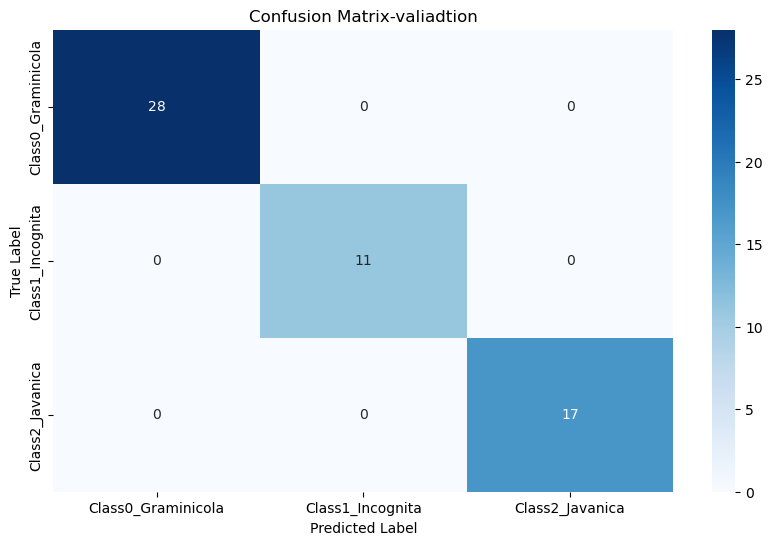

In [246]:
#plot confusion matrix
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix-valiadtion')
plt.show()

In [247]:
# import os
# import glob
# import random
# # Find image files recursively under the training path
# patterns = ['*.jpg', '*.jpeg', '*.png', '*.bmp', '*.tif', '*.tiff']
# image_paths = [
# for pat in patterns:
#     image_paths.extend(glob.glob(os.path.join(train_path, '**', pat), recursive=True))
# image_paths = sorted(set(image_paths))
# if not image_paths:
#     print(f'No image files found under {train_path!r}.')
#     try:
#         print('Contents of training directory:')
#         for entry in sorted(os.listdir(train_path)):
#             print('-', entry)
#     except Exception as e:
#         print('Could not list directory:', e)
# else:
#     n = min(2, len(image_paths))
#     sample_paths = image_paths[:n]  # use the first n images (or replace with random.sample)
#     fig, axes = plt.subplots(1, n, figsize=(6*n, 6))
#     if n == 1:
#         axes = [axes]
#     for ax, pth in zip(axes, sample_paths):
#         try:
#             img = Image.open(pth).convert('RGB')
#             ax.imshow(img)
#             ax.axis('off')
#             ax.set_title(os.path.relpath(pth, train_path))
#         except Exception as e:
#             ax.text(0.5, 0.5, f'Error opening\n{os.path.basename(pth)}:\n{e}', ha='center')
#             ax.axis('off')
#     plt.show()

In [248]:
print("Train transforms:", train_data.transform)
print("Val transforms:  ", val_data.transform)


Train transforms: Compose(
    Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
Val transforms:   Compose(
    Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [249]:
print("train counts:\n", train_df['label'].value_counts().sort_index())
print("val counts:\n", train_df['label'].value_counts().sort_index())

train counts:
 label
0    111
1     44
2     66
Name: count, dtype: int64
val counts:
 label
0    111
1     44
2     66
Name: count, dtype: int64


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8096584..0.6220567].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.6384109..-0.061524976].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.6384109..-0.061524976].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.3472902..0.9131775].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.3472902..0.9131775].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.6212862..-0.34039208].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-

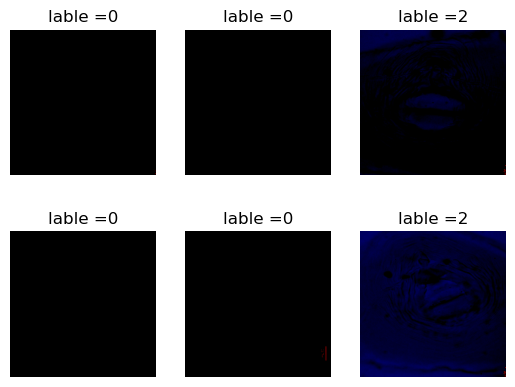

In [250]:
for i in range(6):
    img, lab = val_data[i]
    plt.subplot(2,3,i+1)
    plt.imshow(img.permute(2,1,0).numpy())
    plt.title(f"lable ={lab}")
    plt.axis('off')
plt.show()